# Industry classification

We predicted company industries from supplied business-description embeddings using logistic regression and k-NN. We combined their probabilities and learned confidence from textual and financial evidence. Our financial-calibrated ensemble obtained **78.09% weighted F1**, **0.135585 Brier** and a **67.50% assignment validation score** on 3,171 companies.

In [1]:
import numpy as np
import pandas as pd
import ast

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, LabelEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.decomposition import PCA
import seaborn as sns

In [2]:
from time import perf_counter
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import GroupShuffleSplit
from threadpoolctl import threadpool_limits

threadpool_limits(limits=2)
started = perf_counter()


# Loading Data

We used 31,706 records covering 31,705 company IDs, 25 industries and 768 embedding coordinates. The financial table contained 29,561 records, including 162 duplicate-ID records. We replaced infinities with NaN, retained valid negatives and aggregated financial ratios by company-ID medians. A many-to-one left join preserved companies with missing finances without multiplying rows. We left missing ratios unknown rather than replacing them with zero.

We used company-grouped splits with seed 42: 25,681 fitting, 1,427 tuning, 1,427 calibration and 3,171 validation records. Repeated company IDs stayed together. The split was not stratified. Fitting learned preprocessing, classifiers and financial profiles; tuning selected the voting weight; calibration learned correctness for the fixed system; validation measured its performance. We converted string or vector embeddings to float32.

In [3]:
financial_columns = ['net_profit_margin', 'ebitda_margin', 'asset_turnover']

def prepare_companies(companies, financials=None):
    if financials is not None:
        financials = financials.set_index('id').reindex(columns=financial_columns).replace([np.inf, -np.inf], np.nan)
        financials = financials.groupby('id').median()
        companies = companies.drop(columns=financial_columns, errors='ignore').merge(
            financials, on='id', how='left', validate='many_to_one', sort=False)
    companies = companies.reindex(columns=companies.columns.union(financial_columns, sort=False)).copy()
    companies[financial_columns] = companies[financial_columns].replace([np.inf, -np.inf], np.nan)
    return companies

df = prepare_companies(pd.read_pickle('data/df_train.pkl'), pd.read_pickle('data/df_financials_train.pkl'))

def split(companies, size):
    a, b = next(GroupShuffleSplit(n_splits=1, test_size=size, random_state=42).split(
        companies, groups=companies['id']))
    return companies.iloc[a], companies.iloc[b]

df_train, df_val = split(df, 0.1)
df_fit, df_development = split(df_train, 0.1)
df_tune, df_cal = split(df_development, 0.5)
display(pd.Series([len(d) for d in [df_fit, df_tune, df_cal, df_val]],
                  index=['Fitting', 'Tuning', 'Calibration', 'Validation'], name='Records'))


Fitting        25681
Tuning          1427
Calibration     1427
Validation      3171
Name: Records, dtype: int64

In [4]:
def embeddings(companies):
    values = companies['business_description_embedding'].map(
        lambda value: ast.literal_eval(value) if isinstance(value, str) else value)
    return np.array(values.tolist(), dtype=np.float32)

X_fit, X_tune, X_cal, X_val = [embeddings(d) for d in [df_fit, df_tune, df_cal, df_val]]

In [5]:
df_train.head(3)

,id,industry,business_description_embedding,net_profit_margin,ebitda_margin,asset_turnover
0,42576,Banks,"[0.03411475,-0.03753958,0.023233214,-0.0017205...",0.155503,NaN,0.033292
1,21752,Materials,"[-0.025557408,0.0636078,-0.01350581,-0.0180223...",0.023660,NaN,0.861915
2,804,Commercial & Professional Services,"[0.033574868,-0.020379327,-0.03221274,-0.01133...",0.001364,NaN,1.348739


# Transforming Data (Label Encoding)

### Tasks:

We fitted `LabelEncoder` on fitting industries and reused its mapping on all held-out subsets. We checked that every held-out class occurred in fitting. Encoded integers identify classes without defining an order or distance between industries.

In [6]:
le = LabelEncoder().fit(df_fit['industry'])
assert set(df_tune['industry']) | set(df_cal['industry']) | set(df_val['industry']) <= set(le.classes_)
y_fit, y_tune, y_cal, y_val = [le.transform(d['industry']) for d in [df_fit, df_tune, df_cal, df_val]]
print('Embedding dimensions:', X_fit.shape[1], '| Industries:', len(le.classes_))


Embedding dimensions: 768 | Industries: 25


# Visualize the data

### Tasks:

We inspected class frequencies and projected embeddings with PCA to examine their structure. We interpreted the labelled scatterplot alongside held-out classification results, since visual separation in two dimensions cannot establish predictive performance.

### Class distribution

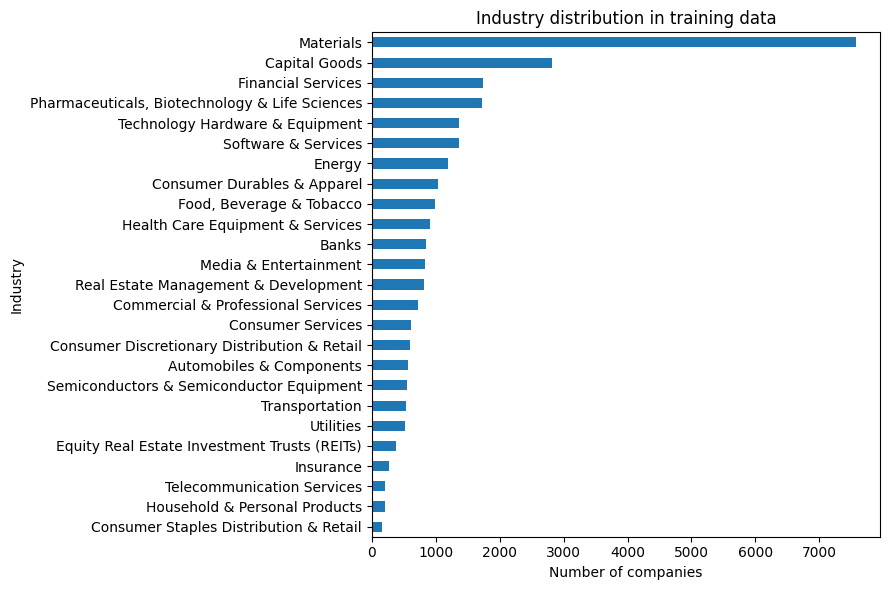

In [7]:
counts = df_train['industry'].value_counts()
counts.sort_values().plot.barh(figsize=(9, 6), title='Industry distribution in training data')
plt.xlabel('Number of companies')
plt.ylabel('Industry')
plt.tight_layout()
plt.show()


We observed 7,570 Materials records (26.5% of the development training portion), compared with 160 for Consumer Staples Distribution & Retail. This roughly 47-fold imbalance motivated macro F1 and per-industry analysis alongside accuracy and weighted F1.

### PCA - Dimensionality reduction and visualization

We fitted PCA on fitting embeddings and transformed held-out subsets with the same fitted projection. We retained 128 components for k-NN and displayed the first two. PCA centers the coordinates; we applied no extra scaling, whitening or normalization. The retained dimension came from the existing implementation, rather than a newly recorded search.

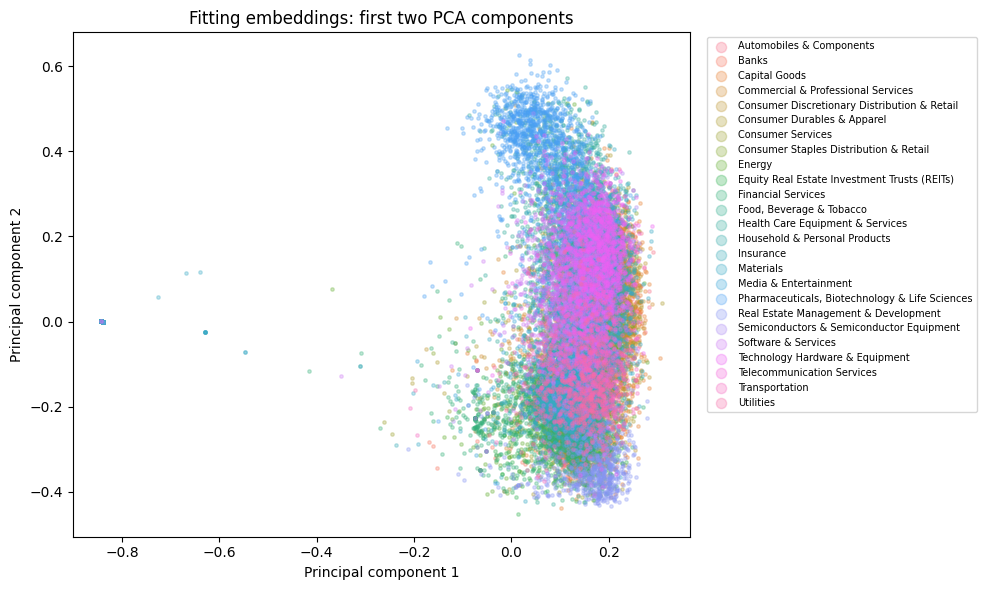

Variance retained (2 / 128 components): 0.25287107 0.8762428


In [8]:
pca = PCA(n_components=128, random_state=42)
X_fit_pca = pca.fit_transform(X_fit)
X_tune_pca, X_cal_pca, X_val_pca = [pca.transform(X) for X in [X_tune, X_cal, X_val]]
plt.figure(figsize=(10, 6))
colors = sns.color_palette('husl', len(le.classes_))
for label, industry in enumerate(le.classes_):
    mask = y_fit == label
    plt.scatter(X_fit_pca[mask, 0], X_fit_pca[mask, 1], s=6, alpha=0.3, color=colors[label], label=industry)
plt.xlabel('Principal component 1')
plt.ylabel('Principal component 2')
plt.title('Fitting embeddings: first two PCA components')
plt.legend(bbox_to_anchor=(1.02, 1), fontsize=7, markerscale=3)
plt.tight_layout()
plt.show()
print('Variance retained (2 / 128 components):', pca.explained_variance_ratio_[:2].sum(),
      pca.explained_variance_ratio_.sum())


We observed an upper pharmaceutical concentration and other local concentrations, with substantial central overlap. The first two components retained 25.287% of variance; all 128 retained 87.624%. Variance retention is not classification accuracy, and overlap in this projection does not rule out separation in other coordinates.

# Fitting and comparing Classifier Models

### Tasks:

We compared a global linear classifier with a local distance-based classifier. We evaluated accuracy, weighted F1 and macro F1, then inspected per-industry reports, normalized confusion matrices and shared errors. Accuracy counts correct records; weighted F1 averages per-class F1 by support, whereas macro F1 gives each industry equal weight.

We fitted `LogisticRegression(C=10, max_iter=1000)` on the original 768-coordinate embeddings and distance-weighted k-NN with 15 neighbors on 128 PCA coordinates. k-NN used Euclidean distance and two jobs; numerical libraries were limited to two threads. We checked that probability columns followed the same class order.

We retained these settings from the existing implementation. C inversely controls regularization; k controls neighborhood size; PCA reduces distance-computation cost while discarding some variance. The available evidence does not establish globally optimal settings.

In [9]:
lr = LogisticRegression(C=10, max_iter=1000).fit(X_fit, y_fit)
knn = KNeighborsClassifier(n_neighbors=15, weights='distance', n_jobs=2).fit(X_fit_pca, y_fit)
assert np.array_equal(lr.classes_, knn.classes_) and np.array_equal(lr.classes_, np.arange(len(le.classes_)))
proba_tune_lr, proba_cal_lr, proba_val_lr = [lr.predict_proba(X) for X in [X_tune, X_cal, X_val]]
proba_tune_knn, proba_cal_knn, proba_val_knn = [knn.predict_proba(X) for X in [X_tune_pca, X_cal_pca, X_val_pca]]

We kept both required classifiers fixed for validation. Per-industry recall and confusion matrices showed where errors concentrated, while class-size correlations and error overlap helped assess imbalance and possible complementarity.

Logistic regression


,precision,recall,f1-score,support
Commercial & Professional Services,0.490196,0.304878,0.375940,82.0
Household & Personal Products,0.470588,0.421053,0.444444,19.0
Consumer Staples Distribution & Retail,0.428571,0.500000,0.461538,18.0
Consumer Discretionary Distribution & Retail,0.612245,0.526316,0.566038,57.0
Capital Goods,0.639241,0.655844,0.647436,308.0
Technology Hardware & Equipment,0.702532,0.627119,0.662687,177.0
Telecommunication Services,0.615385,0.727273,0.666667,22.0
Software & Services,0.682081,0.706587,0.694118,167.0
Semiconductors & Semiconductor Equipment,0.745455,0.650794,0.694915,63.0
Energy,0.750000,0.647482,0.694981,139.0


Industry size / error-rate correlation: -0.36218498049808145


Capital Goods                       Materials                                         28
Technology Hardware & Equipment     Capital Goods                                     21
Materials                           Capital Goods                                     18
Health Care Equipment & Services    Pharmaceuticals, Biotechnology & Life Sciences    15
Commercial & Professional Services  Capital Goods                                     15
Name: Misclassifications, dtype: int64

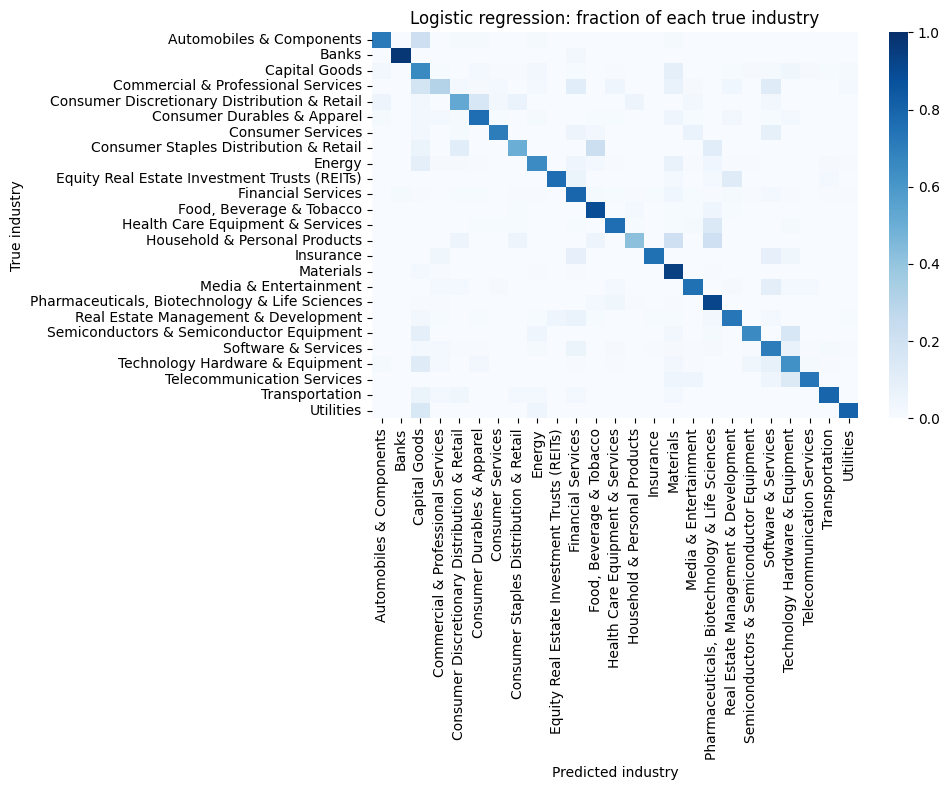

k-NN


,precision,recall,f1-score,support
Commercial & Professional Services,0.612903,0.231707,0.336283,82.0
Consumer Staples Distribution & Retail,0.600000,0.333333,0.428571,18.0
Household & Personal Products,0.416667,0.526316,0.465116,19.0
Consumer Discretionary Distribution & Retail,0.574074,0.543860,0.558559,57.0
Capital Goods,0.619938,0.646104,0.632750,308.0
Semiconductors & Semiconductor Equipment,0.740741,0.634921,0.683761,63.0
Technology Hardware & Equipment,0.723926,0.666667,0.694118,177.0
Energy,0.809524,0.611511,0.696721,139.0
Software & Services,0.733766,0.676647,0.704050,167.0
Real Estate Management & Development,0.673267,0.739130,0.704663,92.0


Industry size / error-rate correlation: -0.28361182194072493


Capital Goods                       Materials              33
Technology Hardware & Equipment     Capital Goods          24
Commercial & Professional Services  Capital Goods          17
Materials                           Capital Goods          16
Technology Hardware & Equipment     Software & Services    15
Name: Misclassifications, dtype: int64

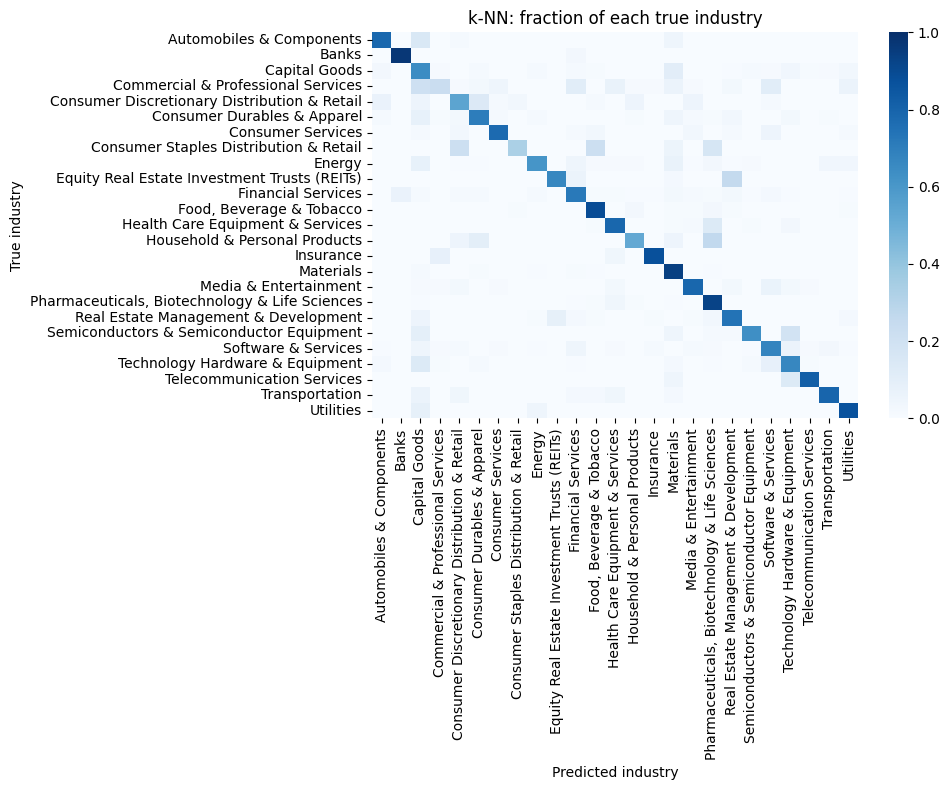

,Accuracy,Weighted F1,Macro F1
Model,,,
Logistic regression,0.781457,0.777788,0.717515
k-NN,0.777042,0.771401,0.710471


Higher validation weighted F1: Logistic regression
Both wrong / only LR wrong / only k-NN wrong: 520 173 187


In [10]:
predictions = {'Logistic regression': proba_val_lr.argmax(axis=1), 'k-NN': proba_val_knn.argmax(axis=1)}
results = []
for name, prediction in predictions.items():
    results.append([name, accuracy_score(y_val, prediction), f1_score(y_val, prediction, average='weighted'),
                    f1_score(y_val, prediction, average='macro')])
    report = pd.DataFrame(classification_report(y_val, prediction, labels=np.arange(len(le.classes_)),
                         target_names=le.classes_, output_dict=True, zero_division=0)).T.loc[le.classes_]
    print(name)
    display(report.sort_values('f1-score'))
    print('Industry size / error-rate correlation:', counts.reindex(report.index).corr(1 - report['recall']))
    cm = confusion_matrix(y_val, prediction, labels=np.arange(len(le.classes_)))
    pairs = pd.DataFrame(cm, index=le.classes_, columns=le.classes_)
    np.fill_diagonal(pairs.values, 0)
    display(pairs.stack().sort_values(ascending=False).head(5).rename('Misclassifications'))
    plt.figure(figsize=(10, 8))
    sns.heatmap(confusion_matrix(y_val, prediction, labels=np.arange(len(le.classes_)), normalize='true'),
                xticklabels=le.classes_, yticklabels=le.classes_, cmap='Blues', vmin=0, vmax=1)
    plt.xlabel('Predicted industry')
    plt.ylabel('True industry')
    plt.title(name + ': fraction of each true industry')
    plt.tight_layout()
    plt.show()
comparison = pd.DataFrame(results, columns=['Model', 'Accuracy', 'Weighted F1', 'Macro F1']).set_index('Model')
display(comparison)
print('Higher validation weighted F1:', comparison['Weighted F1'].idxmax())
errors_lr, errors_knn = predictions['Logistic regression'] != y_val, predictions['k-NN'] != y_val
print('Both wrong / only LR wrong / only k-NN wrong:',
      (errors_lr & errors_knn).sum(), (errors_lr & ~errors_knn).sum(), (~errors_lr & errors_knn).sum())


**Classifier comparison.** Logistic regression achieves 78.15% accuracy and 77.78% weighted F1, ahead of k-NN's 77.70% and 77.14%. Macro F1 is lower (71.75% / 71.05%), showing weaker average performance when industries receive equal weight. For LR, Banks and Materials have F1 of 97.17% and 92.43%; Commercial & Professional Services is much weaker at 37.59%.

Both models often predict Materials for Capital Goods (28 LR / 33 k-NN cases) and Capital Goods for Technology Hardware & Equipment (21 / 24). Training-size/error correlations are -0.362 and -0.284: larger classes tend to have lower error rates, but these correlations do not establish causation. Both classifiers miss 520 records; 173 errors are unique to LR and 187 to k-NN, leaving some complementary information for voting.

# Optional: Confidence Weighted Prediction

## Deliverables:

We combined logistic regression and k-NN and estimated prediction confidence using textual and financial evidence. Our inference function returns a tuple of industry and confidence vectors in input-row order, with confidence in [0,1]. We evaluated reliability and flagged uncertain cases for potential human review.

## Scoring

We evaluated labels and confidence using the supplied `confidence_score` function, preserved below. For each record, correctness is 1 when the predicted industry matches the target and 0 otherwise:

$$\mathrm{Brier}=\frac{1}{n}\sum_i(c_i-\mathbb{1}[\hat y_i=y_i])^2,\qquad \mathrm{score}=F_1^{\mathrm{weighted}}(1-\mathrm{Brier}).$$

Confidence lies in [0,1] and estimates whether the chosen label is correct. It does not weight samples in F1. This Brier evaluates binary correctness, rather than the full multiclass probability vector. Both unjustified certainty and low confidence on correct predictions incur penalties. The assignment score cannot exceed classification weighted F1.

In [11]:
from sklearn.metrics import f1_score


def confidence_score(y_true, y_pred, confidence):
    """
    Score for the confidence weighted prediction task.

    Parameters:
    -----------
    y_true : array-like
        True class labels
    y_pred : array-like
        Predicted class labels
    confidence : array-like
        Confidence for each prediction, in [0, 1]
        (= estimated probability that the prediction is correct)

    Returns:
    --------
    float
        weighted F1 * (1 - Brier score), between 0 and 1 (higher is better)
    """
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    confidence = np.asarray(confidence, dtype=float)

    assert len(y_true) == len(y_pred) == len(confidence), "Inputs must have the same length"
    assert np.all((confidence >= 0) & (confidence <= 1)), "Confidence must be between 0 and 1"

    f1 = f1_score(y_true, y_pred, average="weighted")
    correct = (y_true == y_pred).astype(float)
    brier = np.mean((confidence - correct) ** 2)

    return f1 * (1 - brier)

### Scoring example

A separate C=1 logistic regression illustrates confidence scoring. It obtained approximately 0.6577 using model confidence and 0.5972 using confidence always equal to one. These illustrative scores are separate from the final ensemble result.

In [12]:
X_train = X_fit
y_train = y_fit


In [13]:
# Example: evaluate a model on the validation set
# (requires y_train and y_val from the label encoding task)

example_model = LogisticRegression(max_iter=1000).fit(X_train, y_train)

y_proba = example_model.predict_proba(X_val)
y_pred = example_model.classes_[np.argmax(y_proba, axis=1)]
confidence = np.max(y_proba, axis=1)  # probability of the predicted class

print("Score with model confidence:  {:.4f}".format(confidence_score(y_val, y_pred, confidence)))
print("Score with confidence = 1.0:  {:.4f}".format(confidence_score(y_val, y_pred, np.ones(len(y_pred)))))

Score with model confidence:  0.6577
Score with confidence = 1.0:  0.5972


### Soft voting

We selected the LR probability weight on tuning weighted F1 alone. Weights 0.25, 0.50 and 0.75 gave 0.791847, 0.783686 and 0.782247 respectively, selecting 0.25 LR and 0.75 k-NN. We fixed this combination before learning confidence. Complementary errors motivated voting; they did not guarantee an improvement.

In [14]:
weights = [0.25, 0.5, 0.75]
tuning_f1 = [f1_score(y_tune, (w * proba_tune_lr + (1 - w) * proba_tune_knn).argmax(axis=1),
                      average='weighted') for w in weights]
lr_weight = weights[np.argmax(tuning_f1)]
display(pd.DataFrame({'LR weight': weights, 'Tuning weighted F1': tuning_f1}))
print('Selected LR weight:', lr_weight)


,LR weight,Tuning weighted F1
0,0.25,0.791847
1,0.50,0.783686
2,0.75,0.782247


Selected LR weight: 0.25


### Financial distributions

We compared fitting-only counts, medians and ratio distributions across industries. Symmetric log axes retained negative values; hiding outlier dots improved readability without removing observations from the profiles.

net_profit_margin            \
                                                           count    median   
industry                                                                     
Automobiles & Components                                     475  0.034077   
Banks                                                        710  0.245811   
Capital Goods                                               2276  0.039592   
Commercial & Professional Services                           532  0.033262   
Consumer Discretionary Distribution & Retail                 473  0.017686   
Consumer Durables & Apparel                                  832  0.031132   
Consumer Services                                            469  0.028669   
Consumer Staples Distribution & Retail                       140  0.022693   
Energy                                                       795  0.043417   
Equity Real Estate Investment Trusts (REITs)                 323  0.252600   
Financial Services                                          1115  0.259259   
Food, Beverage & Tobacco                                     782  0.038511   
Health Care Equipment & Services                             678 -0.003701   
Household & Personal Products                                161  0.035555   
Insurance                                                    211  0.079118   
Materials                                                   5438  0.049562   
Media & Entertainment                                        620 -0.021711   
Pharmaceuticals, Biotechnology & Life Sciences              1074 -0.188698   
Real Estate Management & Development                         636  0.080751   
Semiconductors & Semiconductor Equipment                     457  0.042345   
Software & Services                                         1012  0.002503   
Technology Hardware & Equipment                             1144  0.025385   
Telecommunication Services                                   154  0.033975   
Transportation                                               434  0.070571   
Utilities                                                    414  0.085487   

                                               ebitda_margin            \
                                                       count    median   
industry                                                                 
Automobiles & Components                                 133  0.092523   
Banks                                                    209  0.256049   
Capital Goods                                            727  0.106101   
Commercial & Professional Services                       290  0.097789   
Consumer Discretionary Distribution & Retail             277  0.071807   
Consumer Durables & Apparel                              272  0.090690   
Consumer Services                                        260  0.147591   
Consumer Staples Distribution & Retail                    66  0.050672   
Energy                                                   338  0.165206   
Equity Real Estate Investment Trusts (REITs)             221  0.580373   
Financial Services                                       639  0.355395   
Food, Beverage & Tobacco                                 310  0.091367   
Health Care Equipment & Services                         411  0.004134   
Household & Personal Products                             78  0.105431   
Insurance                                                121  0.129391   
Materials                                                732  0.076083   
Media & Entertainment                                    324  0.040945   
Pharmaceuticals, Biotechnology & Life Sciences           572 -0.958235   
Real Estate Management & Development                     253  0.221348   
Semiconductors & Semiconductor Equipment                 102  0.035120   
Software & Services                                      543  0.016398   
Technology Hardware & Equipment                          309  0.044596   
Telecommunic

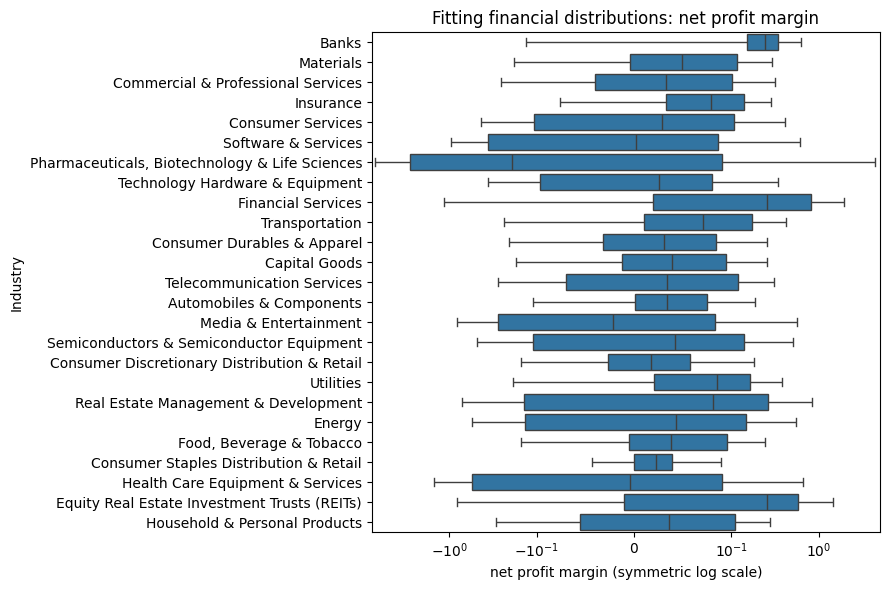

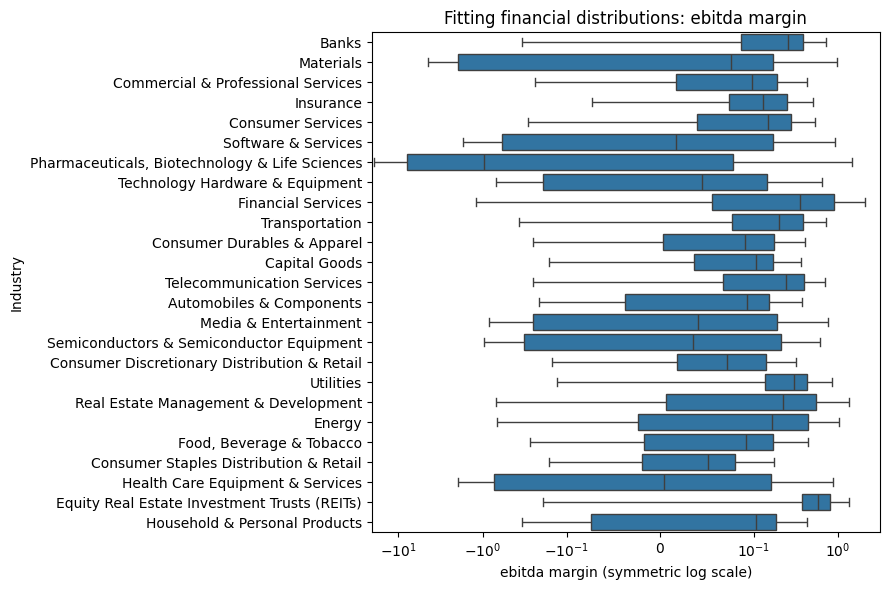

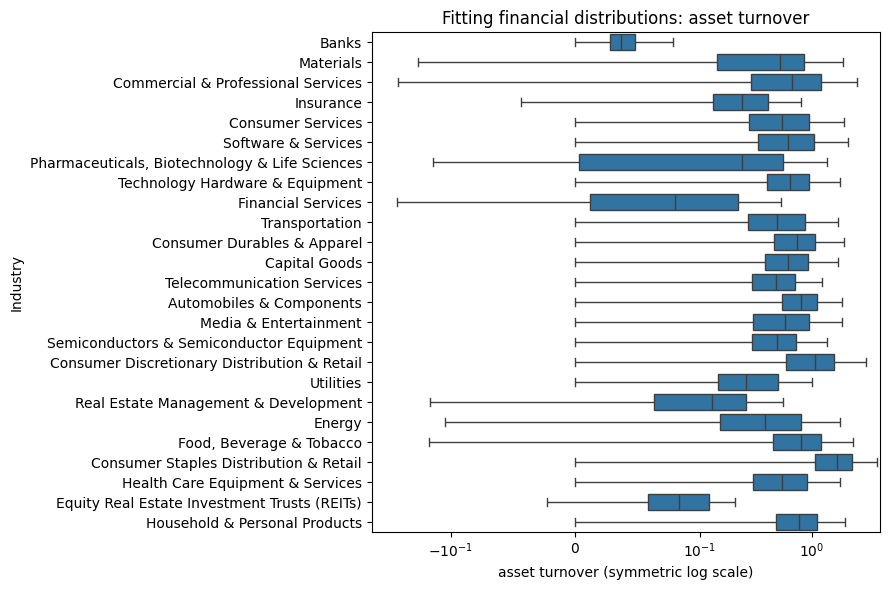

In [15]:
display(df_fit.groupby('industry')[financial_columns].agg(['count', 'median']))
for column in financial_columns:
    plt.figure(figsize=(9, 6))
    sns.boxplot(data=df_fit, x=column, y='industry', showfliers=False)
    plt.xscale('symlog', linthresh=0.1)
    plt.xlabel(column.replace('_', ' ') + ' (symmetric log scale)')
    plt.ylabel('Industry')
    plt.title('Fitting financial distributions: ' + column.replace('_', ' '))
    plt.tight_layout()
    plt.show()


**Observed financial distributions.** Ratios overlap broadly, so they support confidence rather than determine an industry. Pharmaceutical profit margins include substantial negative values. Banks and REITs have much lower typical asset turnover than Consumer Staples Distribution & Retail. Raw EBITDA margin is missing for 19,279 of 29,561 financial records (65.2%), with another 824 infinite values; coverage must be represented explicitly.

### Financial evidence and confidence calibration

We built sorted financial references from fitting data for each industry and ratio, requiring at least 20 finite observations. We compared each new ratio with the **predicted** industry's profile. Middle ranks handled ties: with left and right insertion positions and m references, we used q = (0.5 × (left + right) + 0.5)/(m + 1), then compatibility = 2 × min(q, 1 − q).

We averaged available compatibilities. With no usable ratio, we used compatibility 0.5 and coverage zero. This empirical index limits the influence of extreme magnitudes without assuming normality; it is neither a correctness probability nor a formally combined p-value.

We fitted binary logistic calibrators on calibration correctness after fixing the classifiers and voting weight. Text calibration used maximum vote, the gap to second place and classifier agreement. Financial calibration added compatibility and the fraction of usable ratios. These models minimize regularized log-loss, so we checked Brier empirically rather than assuming it must improve. We kept the base models frozen afterward.

In [16]:
profiles = {(industry, column): np.sort(df_fit.loc[df_fit['industry'] == industry, column].dropna())
            for industry in le.classes_ for column in financial_columns}

def confidence_features(companies, proba_lr, proba_knn):
    votes = lr_weight * proba_lr + (1 - lr_weight) * proba_knn
    prediction = votes.argmax(axis=1)
    top = np.sort(votes, axis=1)
    predicted_industries = le.inverse_transform(prediction)
    total, available = np.zeros(len(companies)), np.zeros(len(companies))
    for industry in le.classes_:
        for column in financial_columns:
            reference = profiles[industry, column]
            if len(reference) < 20:
                continue
            values = companies[column].to_numpy()
            mask = (predicted_industries == industry) & np.isfinite(values)
            left = np.searchsorted(reference, values[mask], side='left')
            right = np.searchsorted(reference, values[mask], side='right')
            percentile = (0.5 * (left + right) + 0.5) / (len(reference) + 1)
            total[mask] += 2 * np.minimum(percentile, 1 - percentile)
            available[mask] += 1
    compatibility = np.divide(total, available, out=np.full(len(companies), 0.5), where=available > 0)
    features = np.column_stack([top[:, -1], top[:, -1] - top[:, -2],
                               proba_lr.argmax(axis=1) == proba_knn.argmax(axis=1),
                               compatibility, available / len(financial_columns)])
    return prediction, features

pred_cal, features_cal = confidence_features(df_cal, proba_cal_lr, proba_cal_knn)
correct_cal = (pred_cal == y_cal).astype(int)
text_calibrator = LogisticRegression().fit(features_cal[:, :3], correct_cal)
finance_calibrator = LogisticRegression().fit(features_cal, correct_cal)

def predict_industry(companies, financials=None):
    companies = prepare_companies(companies, financials)
    X = embeddings(companies)
    prediction, features = confidence_features(companies, lr.predict_proba(X), knn.predict_proba(pca.transform(X)))
    return le.inverse_transform(prediction), finance_calibrator.predict_proba(features)[:, 1]


### Confidence comparison

We evaluated raw, text-calibrated and financial-calibrated confidence on the same validation companies. Their industry labels were identical: financial evidence changed confidence only. The financial-calibrated ensemble was the predefined final candidate; this table evaluated it rather than selecting it from validation.

The retained output column `Official score` denotes the assignment validation score defined above.

In [17]:
pred_val, features_val = confidence_features(df_val, proba_val_lr, proba_val_knn)
confidence_methods = {'Raw ensemble': features_val[:, 0],
                      'Text-calibrated ensemble': text_calibrator.predict_proba(features_val[:, :3])[:, 1],
                      'Financial-calibrated ensemble': finance_calibrator.predict_proba(features_val)[:, 1]}
methods = {name: (pred_val, c) for name, c in confidence_methods.items()}
methods['Logistic regression'] = (predictions['Logistic regression'], proba_val_lr.max(axis=1))
methods['k-NN'] = (predictions['k-NN'], proba_val_knn.max(axis=1))
bonus_results = []
for name, (prediction, confidence) in methods.items():
    bonus_results.append([name, f1_score(y_val, prediction, average='weighted'),
                          np.mean((confidence - (prediction == y_val)) ** 2),
                          confidence_score(y_val, prediction, confidence)])
display(pd.DataFrame(bonus_results, columns=['Method', 'Weighted F1', 'Brier', 'Official score']).set_index('Method'))

,Weighted F1,Brier,Official score
Method,,,
Raw ensemble,0.780881,0.137380,0.673604
Text-calibrated ensemble,0.780881,0.135923,0.674742
Financial-calibrated ensemble,0.780881,0.135585,0.675006
Logistic regression,0.777788,0.137087,0.671163
k-NN,0.771401,0.141496,0.662251


**Confidence comparison.** The ensemble's labels stay fixed at 78.09% weighted F1. Raw, text-calibrated and financial-calibrated confidence yield Brier scores of 0.137380, 0.135923 and 0.135585, and assignment scores of 67.36%, 67.47% and 67.50%. The financial gain is small. The financial variant was specified before evaluating this table; it is not chosen by taking the highest validation score.

### Reliability, human review and inference

We compared mean confidence with observed accuracy in bins, retaining counts to show the strength of evidence. We used confidence below 0.8 as an illustrative review policy. Flagged records remained in every score.

Our `predict_industry(companies, financials=None)` returned industry names and confidence in input-row order, without reading targets or refitting. It accepted prejoined ratios or a separate financial table that overrode them, converted missing ratios to NaN and preserved caller inputs. It did not retrieve training finances implicitly.

,Count,Mean_confidence,Accuracy
Bin,,,
"(0.2, 0.3]",11,0.280748,0.363636
"(0.3, 0.4]",128,0.364461,0.437500
"(0.4, 0.5]",258,0.449690,0.449612
"(0.5, 0.6]",235,0.548473,0.557447
"(0.6, 0.7]",237,0.649352,0.628692
"(0.7, 0.8]",300,0.752414,0.723333
"(0.8, 0.9]",617,0.857856,0.820097
"(0.9, 1.0]",1385,0.937450,0.948736


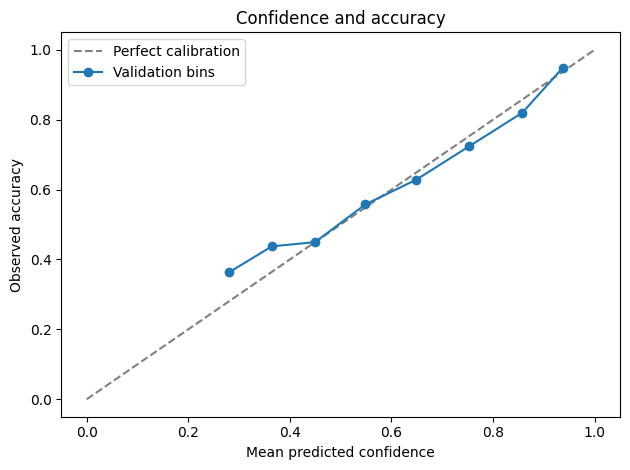

,Count,Accuracy
Human review,,
False,2002,0.909091
True,1169,0.575706


Flagged share: 0.3686534216335541 | Errors captured: 496 of 678


,ID,Predicted industry,Confidence
0,21057,Capital Goods,0.710822
1,24720,Materials,0.950146
2,24392,Consumer Services,0.908970


,Count,Accuracy
Embedding seen during fitting,,
False,2716,0.751473
True,455,0.993407


Whole notebook elapsed seconds: 78.4


In [18]:
confidence_val = confidence_methods['Financial-calibrated ensemble']
outcomes = pd.DataFrame({'Confidence': confidence_val, 'Correct': pred_val == y_val})
outcomes['Bin'] = pd.cut(confidence_val, np.linspace(0, 1, 11), include_lowest=True)
reliability = outcomes.groupby('Bin', observed=True).agg(
    Count=('Correct', 'size'), Mean_confidence=('Confidence', 'mean'), Accuracy=('Correct', 'mean'))
display(reliability)
plt.plot([0, 1], [0, 1], '--', color='gray', label='Perfect calibration')
plt.plot(reliability['Mean_confidence'], reliability['Accuracy'], 'o-', label='Validation bins')
plt.xlabel('Mean predicted confidence')
plt.ylabel('Observed accuracy')
plt.title('Confidence and accuracy')
plt.legend()
plt.tight_layout()
plt.show()
review = confidence_val < 0.8
outcomes['Human review'] = review
display(outcomes.groupby('Human review').agg(Count=('Correct', 'size'), Accuracy=('Correct', 'mean')))
print('Flagged share:', review.mean(), '| Errors captured:', np.sum(review & (pred_val != y_val)),
      'of', np.sum(pred_val != y_val))
example = df_val.drop(columns='industry').head(3)
industries, confidences = predict_industry(example)
display(pd.DataFrame({'ID': example['id'].to_numpy(), 'Predicted industry': industries, 'Confidence': confidences}))
seen_embedding = df_val['business_description_embedding'].isin(df_fit['business_description_embedding'])
display(pd.DataFrame({'Embedding seen during fitting': seen_embedding.to_numpy(), 'Correct': pred_val == y_val})
        .groupby('Embedding seen during fitting').agg(Count=('Correct', 'size'), Accuracy=('Correct', 'mean')))
print('Whole notebook elapsed seconds:', round(perf_counter() - started, 1))


**Reliability and review.** In the highest bin, mean confidence is 93.74% and accuracy is 94.87% across 1,385 cases. The 0.8–0.9 bin is overconfident (85.79% confidence versus 82.01% accuracy); the lowest populated bin contains only 11 cases and is noisy. Confidence below 0.8 flags 1,169 records (36.9%): accuracy is 57.57% there versus 90.91% among unflagged records. The policy captures 496 of 678 errors (73.2%) without excluding any record from scoring.

### Final assignment validation score

We evaluated the predefined financial-calibrated ensemble with the exact supplied scorer. We obtained weighted F1 0.7808814718742704, Brier 0.135584565225789 and assignment score **0.6750059970173232**. This result evaluates the final ensemble on local validation data.

In [19]:
print('MAIN GRADED SCORE (LOCAL VALIDATION)')
print('Final candidate: financial-calibrated ensemble')
print('N:', len(y_val))
print(f'Weighted F1: {f1_score(y_val, pred_val, average="weighted"):.2%}')
print(f'Brier: {np.mean((confidence_val - (pred_val == y_val)) ** 2):.6f}')
print(f'Official confidence_score: {confidence_score(y_val, pred_val, confidence_val):.2%}')


MAIN GRADED SCORE (LOCAL VALIDATION)
Final candidate: financial-calibrated ensemble
N: 3171
Weighted F1: 78.09%
Brier: 0.135585
Official confidence_score: 67.50%


## Results and limitations

We found logistic regression to be the stronger required standalone classifier. Voting improved weighted F1 by about 0.31 percentage points over LR; financial calibration added only 0.026 percentage points of assignment score over text calibration. These modest gains on one split do not establish robust superiority across datasets.

We used the supplied 31,706 records; the assignment's 40,000+ description concerns the wider dataset. We found 4,578 repeated embedding records and 17 identical-embedding groups with conflicting labels. Despite disjoint company IDs, 455 validation records shared exact fitting embeddings: accuracy was 99.34% on these and 75.15% on 2,716 unseen embeddings. Our evaluation therefore concerns new IDs, not necessarily entirely new descriptions. Validation was also inspected during earlier development and is not an untouched private test.

The verified main execution took 87.3 seconds including verification and the supplied example. Sampled summed runner-plus-kernel RSS reached an upper bound of 1.48 GiB, potentially counting shared pages twice. These Linux cloud measurements do not certify the 45-minute / 16 GB requirement on the intended laptop. AI assistance was used in preparing the project.